# Init:

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [78]:
from knowledge_maze.create_dataset.load_datasets import *

# Load all the input datasets, insert destanation path if saving is required.
tqa_dataset = load_tqa(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_nq(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_sqd(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

total_pairs = len(tqa_dataset) + len(nq_dataset) + len(sqd_dataset)
print(f'Loaded {total_pairs} question-answer pairs in total.')

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Daniel\\Desktop\\Thesis_Experiment\\QA_Datasets\\trivia_qa_train.json'

In [2]:
# Load from saved dataset:
tqa_dataset = load_json(f"{REPO_PATH}\data_files\extracted_nq.json")
nq_dataset = load_json(f"{REPO_PATH}\data_files\extracted_squad.json")
sqd_dataset = load_json(f"{REPO_PATH}\data_files\extracted_triviaQA.json")

# 2. Classify answers:
Classify answers by types - Wikipedia entities, numbers, dates and free-form.
We will merge all the candidate datasets and discard the free-form answer, also normalize the answers for easier comparison later.

In [3]:
from knowledge_maze.create_dataset.answer_classification import classify_dataset_answers

print('Processing TriviaQA:')
tqa_answer_types = await classify_dataset_answers(tqa_dataset, output_path=f"{REPO_PATH}\data_files\\tqa_answer_types.json")
print('Processing Natural Questions:')
nq_answer_types = await classify_dataset_answers(nq_dataset, output_path=f"{REPO_PATH}\data_files\\nq_answer_types.json")
print('Processing SQuAD:')
sqd_answer_types = await classify_dataset_answers(sqd_dataset, output_path=f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Processing TriviaQA:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 78260/78260 [03:16<00:00, 398.08it/s]


Processing Natural Questions:


Classifying Answers: 100%|████████████████████████████████████████████████████| 106926/106926 [04:22<00:00, 407.29it/s]


Processing SQuAD:


Classifying Answers: 100%|██████████████████████████████████████████████████████| 86821/86821 [03:09<00:00, 459.15it/s]


In [4]:
# Load from saved dataset:
tqa_answer_types = load_json(f"{REPO_PATH}\data_files\\tqa_answer_types.json")
nq_answer_types = load_json(f"{REPO_PATH}\data_files\\nq_answer_types.json")
sqd_answer_types = load_json(f"{REPO_PATH}\data_files\\sqd_answer_types.json")

Merged dataset contains 209055 Q-A pairs out of original 272007(77%).


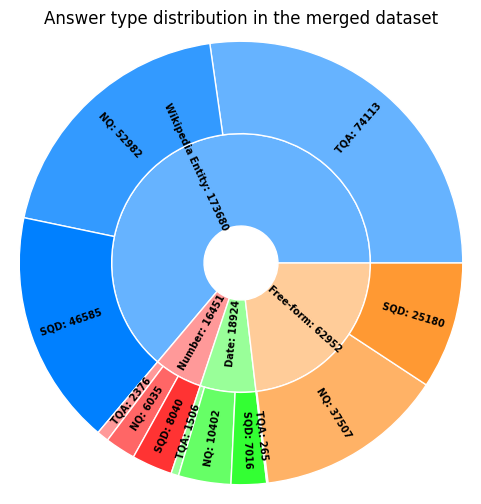

In [4]:
# Merge datasets and visualize results:
from knowledge_maze.create_dataset.answer_classification import merge_datasets

merged_dataset = merge_datasets({
                                     'TQA': tqa_answer_types,
                                     'NQ': nq_answer_types,
                                     'SQD': sqd_answer_types
                                },
                                output_path=f"{REPO_PATH}\data_files\\merged_dataset.json",
                                verbose=True)

In [10]:
# Print exapmles:
from random import choices

for sample in choices(merged_dataset, k=10):
    print(f"Question: {sample['Question']}")
    print(f"Answer: {sample['Answer']}")
    print(f"Type: {sample['Answer type']}")
    print(f"Normalized: {sample['Normalized answer']}")
    print(f"=" * 50)

Question: when did snow white and the seven dwarfs come out
Answer: 1937
Type: Date
Normalized: {'category': 'year', 'parsed_value': '1937'}
Question: What city in Rhode Island is famous for its many mansions built during the late 1800's?
Answer: Newport
Type: Wikipedia Entity
Normalized: Newport
Question: Erik the Red from Norway founded the first successful Norse settlement on Greenland, and then his son Leif continued the tradition of exploring west and landed where?
Answer: North America
Type: Wikipedia Entity
Normalized: North America
Question: What royal park shares a border with its neighbor, the park known as Kensington Gardens?
Answer: Hyde Park
Type: Wikipedia Entity
Normalized: Hyde Park
Question: How many earthquakes occurred on March 5, 2012?
Answer: twelve
Type: Number
Normalized: 12
Question: The Battle of Flodden took place in September 1513 in which English county?
Answer: Northumberland
Type: Wikipedia Entity
Normalized: Northumberland
Question: who won second place i

# 3. Group questions:

In [37]:
# Load from saved dataset:
merged_dataset = load_json(f"{REPO_PATH}\data_files\\merged_dataset.json")

In [38]:
import matplotlib.pyplot as plt
%matplotlib inline
from tqdm import tqdm
from knowledge_maze.create_dataset.cluster_questions import *

In [39]:
# Divide by answer type:
ent_data = []
num_data = []
date_data = []
for sample in merged_dataset:
    if sample['Answer type'] == 'Wikipedia Entity':
        ent_data.append(sample)
    elif sample['Answer type'] == 'Number':
        num_data.append(sample)
    else:
        date_data.append(sample)

In [53]:
# Cluster question by answer:
ent_clusters = cluster_wiki_entities(ent_data)
num_clusters = cluster_numerical_values(num_data)
date_clusters = cluster_date_values(date_data)
print(f'Total candidate clusters:')
print(f'Entities: {len(ent_clusters)} with mean cluster size of: {np.mean([len(value) for value in ent_clusters.values()]):.2f}')
print(f'Numerical: {len(num_clusters)} with mean cluster size of: {np.mean([len(value) for value in num_clusters.values()]):.2f}')
print(f'Date & Time: {len(date_clusters)} with mean cluster size of: {np.mean([len(value) for value in date_clusters.values()]):.2f}')

Total candidate clusters:
Entities: 14198 with mean cluster size of: 7.85
Numerical: 15 with mean cluster size of: 1096.73
Date & Time: 960 with mean cluster size of: 19.18


## 3.1 - Cluster and filter entity questions:

In [54]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
entity_reasoning_chains = await create_paths(ent_clusters, output_path=f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

Generating question embeddings: 100%|██████████████████████████████████████████████████| 55/55 [02:34<00:00,  2.82s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████| 14198/14198 [00:12<00:00, 1180.14it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████| 14198/14198 [00:00<00:00, 716020.73it/s]


In [214]:
# Load from folder:
entity_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\entity_reasoning_chains.json")

## 3.2 - Create numerical questions reasoning paths:

In [50]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
numerical_reasoning_chains = await create_paths(num_clusters, output_path=f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:23<00:00,  2.61s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 15/15 [00:34<00:00,  2.27s/it]
Splitting large clusters: 100%|██████████████████████████████████████████████████████| 15/15 [00:00<00:00, 2753.61it/s]


In [216]:
# Load from folder:
numerical_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\numerical_reasoning_chains.json")

## 3.3 - Create date & time questions reasoning paths:

In [47]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
date_reasoning_chains = await create_paths(date_clusters, output_path=f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 9/9 [00:22<00:00,  2.53s/it]
Creating similarity graphs and filtering questions: 100%|███████████████████████████| 960/960 [00:01<00:00, 482.08it/s]
Splitting large clusters: 100%|██████████████████████████████████████████████████| 960/960 [00:00<00:00, 243104.02it/s]


In [90]:
# Load from folder:
date_reasoning_chains = load_json(f"{REPO_PATH}\data_files\\date_reasoning_chains.json")

## 3.4 - Show clusters distribution & display graph examples:

In [55]:
# Merge & save all clusters into one dataset:
reasoning_chains = list(np.concatenate([entity_reasoning_chains, numerical_reasoning_chains, date_reasoning_chains]))
output_path = f"{REPO_PATH}\data_files\\reasoning_chains.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    json.dump(reasoning_chains, out_file)

In [240]:
# Load from folder:
reasoning_chains = load_json(f"{REPO_PATH}\data_files\\reasoning_chains.json")

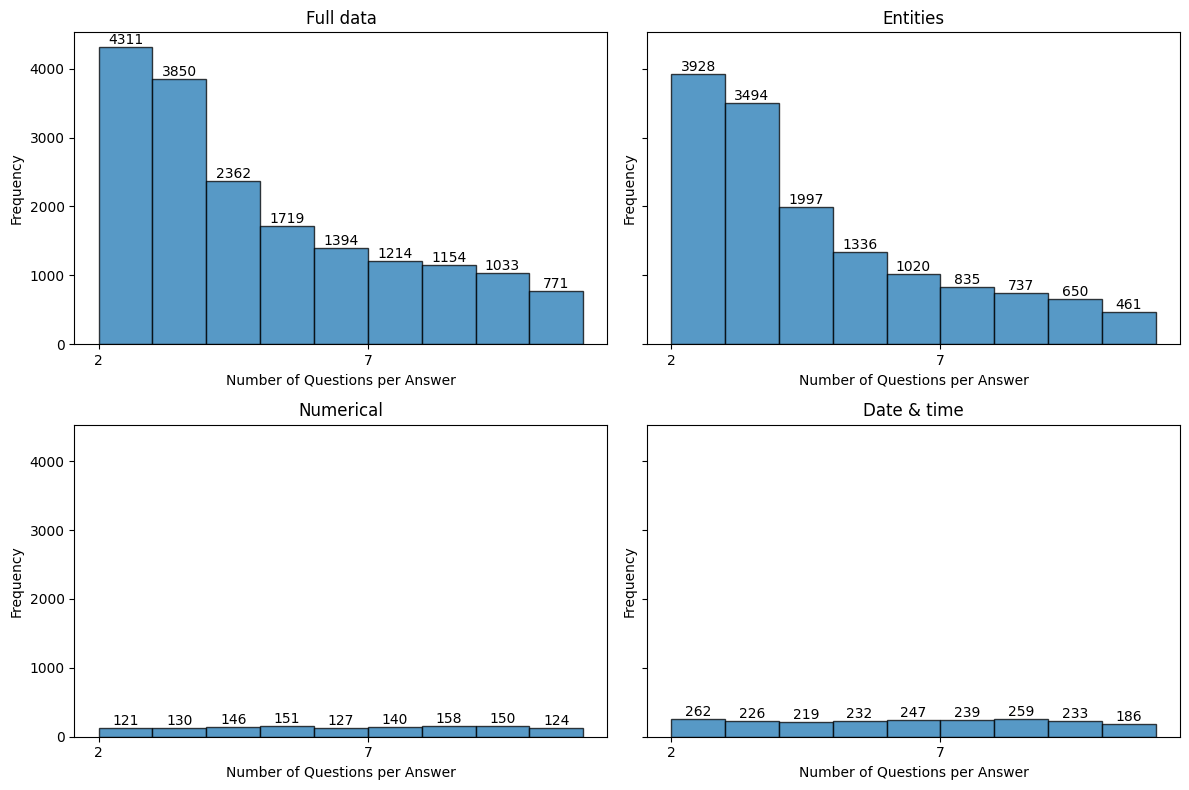

In [56]:
from knowledge_maze.create_dataset.create_reasoning_path import plot_clusters_distribution
plot_clusters_distribution({
    'Full data': reasoning_chains,
    'Entities': entity_reasoning_chains,
    'Numerical': numerical_reasoning_chains,
    'Date & time': date_reasoning_chains
})

In [57]:
from random import choice
# Plot random clusters:
print('=' * 50)
print('Entitity Cluster:')
print('=' * 50)
ent_sample = choice(entity_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Numerical Cluster:')
print('=' * 50)
ent_sample = choice(numerical_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)
print('Date & time Cluster:')
print('=' * 50)
ent_sample = choice(date_reasoning_chains)
print(f"Answer: {ent_sample['Answer']}")
print("List of questions:")
for question in ent_sample['Questions']:
    print(f"- {question}")
print('=' * 50)

Entitity Cluster:
Answer: The Grapes of Wrath
List of questions:
- For her role in which film did Jane Darwell win the 'Oscar' for Best Supporting Actress in 1940 when aged 61?
- """To the red country and part of the grey country of Oklahoma, the last rains came gently, and they did not cut the scarred earth ""is the first line of which novel?"
- What famous John Steinbeck novel featured the travels of Tom Joad?
Numerical Cluster:
Answer: (11, 50)
List of questions:
- What was the name of the room that the first exhibition of Cubists took place?
- What percentage of Norfolk Island is a permanent pasture?
- How many foreign supporters did Burke think a French royalist was worth?
- How many administrative divisions does Samoa have?
- How many Fono members are there?
- How many foreign trips did Montini make as Cardinal?
- How many of Switzerland's mountains are at least 4000 meters above sea level?
- According to the Federal Constitution, how many cantons are equal in status?
Date & time

Answer: Virat Kohli
Questions before filtering:
1. who has scored the most t20 runs for india
2. who is the indian cricket team captain 2018
3. who is the captain of indian cricket team right now
4. who won icc cricketer of the year award
5. who has been named as the cricketer of the year in the icc annual awards
6. which player highest numbers of runs in ipl history
7. who is the captain of india in cricket
8. which indian captain has won the maximum matches against sri lanka
9. who has been wisdens leading cricketer in the world for 2016
10. who scored most runs in t20 for india
11. who is the vice captain of india 2017


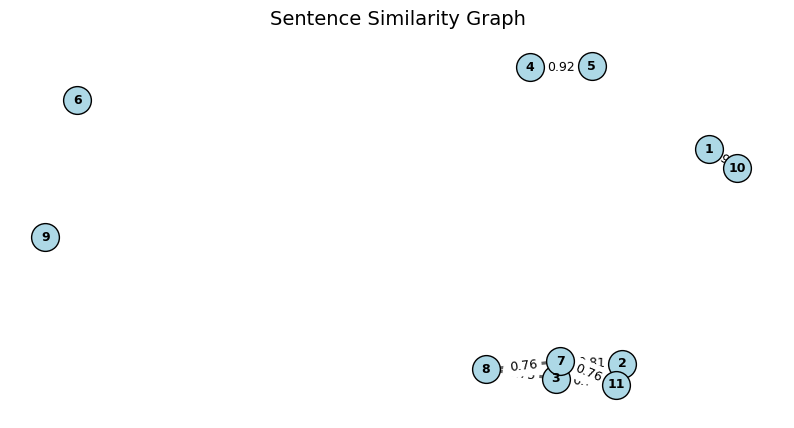

Questions after filtering:
1. who has been named as the cricketer of the year in the icc annual awards
2. which player highest numbers of runs in ipl history
3. which indian captain has won the maximum matches against sri lanka
4. who has been wisdens leading cricketer in the world for 2016
5. who scored most runs in t20 for india
6. who is the vice captain of india 2017


In [80]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(ent_clusters, entity_questions_embeddings)

# 4. Structure Data & Generate Counter Answers:

**Dataset Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}
```

In [353]:
from knowledge_maze.create_dataset.create_data import process_data_to_list
structured_entities = await process_data_to_list(entity_reasoning_chains[:50], 'Wikipedia Entity')
structured_numericals = await process_data_to_list(numerical_reasoning_chains[:50], 'Numerical')
structured_dates = await process_data_to_list(date_reasoning_chains[:50], 'Date & Time')
# Merge all data:
knowledge_maze_qa = list(np.concatenate([structured_entities, structured_numericals, structured_dates]))
# Save Dataset:
# output_path = f"{REPO_PATH}\data_files\\knowledge_maze_qa.json"
# with open(output_path, "w", encoding="utf-8") as out_file:
#     json.dump(knowledge_maze_qa, out_file)

100%|██████████████████████████████████████████████████████████████████████████████████| 50/50 [00:02<00:00, 22.56it/s]
C:\Users\Daniel\AppData\Local\Temp\ipykernel_6040\4269715345.py:4: RuntimeWarning: coroutine 'process_data_to_list' was never awaited
  structured_dates = await process_data_to_list(date_reasoning_chains[:50], 'Date & Time')


In [ ]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\\knowledge_maze_qa.json")

In [356]:
random.choice(knowledge_maze_qa)

{'ID': '2a401c71-ace3-4d62-abaa-654f825b78d0',
 'Question': 'In the book ‘the Sign of Four” Sherlock Holmes describes the cocaine with which he is injecting himself as a certain ‘percent solution’. It is also the title of a book by Nicholas Heyer published in 1974 and a film adaptation in 1976. What is the number of this percent solution?',
 'Answer': {'Memory answer': 7,
  'Counter answer 1': 5,
  'Counter answer 2': 3,
  'Distractor answer': 9},
 'Answer type': 'Numerical',
 'Reasoning path 1': [{'Previous question': 'In the book ‘the Sign of Four” Sherlock Holmes describes the cocaine with which he is injecting himself as a certain ‘percent solution’. It is also the title of a book by Nicholas Heyer published in 1974 and a film adaptation in 1976. What is the number of this percent solution?',
   'Next question': 'How many symphonies did the composer Sir Edward Elgar complete?',
   'Paragraph': '91222125-1ab9-48b7-8edb-1bcbd9eb7c4e'},
  {'Previous question': 'How many symphonies did

# Drafts:

In [267]:
from knowledge_maze.tools.api_tools import *
import asyncio

# Define the system prompt
system_prompt = "You are an expert assistant that provides concise and factual answers."

# Initialize the GPT API client
gpt_client = gptAPI(system_prompt=system_prompt, model="gpt-4o-mini")

# Example queries
queries = [
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "Describe the history of the Roman Empire in 3 sentences.",
    "Describe the history of the Roman Empire in 3 sentences.",
    "Describe the history of the Roman Empire in 3 sentences.",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
    "What is the capital of France?",
    "Explain the theory of relativity in simple terms.",
    "Who was the first person to walk on the moon?",
    "What is the boiling point of water?",
]

# Run asynchronously and track usage
results = await gpt_client.async_run(queries)

# Display the results
for i, response in enumerate(results):
    print(f"Response {i + 1}: {response}")

Usage cost: 0.0019$ (Estimated: 0.00$): 100%|██████████████████████████████████████████| 27/27 [00:17<00:00,  1.56it/s]

Response 1: The capital of France is Paris.
Response 2: The theory of relativity, developed by Albert Einstein, consists of two main parts: special relativity and general relativity.

1. **Special Relativity** (1905): This part focuses on how time and space are linked for objects moving at constant speeds, especially those close to the speed of light. Key ideas include:
   - **Time Dilation**: Time moves slower for objects moving very fast compared to stationary observers. For example, if you travel in a spaceship at near-light speed, you would age more slowly than people on Earth.
   - **Length Contraction**: Objects moving at high speeds appear shorter in the direction of motion to a stationary observer.
   - **Mass-Energy Equivalence**: Expressed in the famous equation E=mc², it shows that mass can be converted into energy and vice versa.

2. **General Relativity** (1915): This part expands the theory to include gravity. It describes gravity not as a force, but as a curvature of spa

In [ ]:
{
    'Question': '',
    'Answer type': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Reasoning path 1':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ],
    'Reasoning path 2':[
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''},
        {'Previous Sub-question': '', 'Next Sub-question': '', 'Paragraph': ''}
    ]
    'Distractor paragraphs': []
}

In [66]:
process_data_to_list(entity_reasoning_chains[2:4])

{'Answer': 'David Bowie', 'Questions': ['Which musician played Nikola Tesla in the 2006 film The Prestige?', 'Which pop star did model Iman marry in 1992?', "The first line of the song Do They Know It's Christmas? by Band Aid was originally intended for which singer, who finally got to sing it during Live Aid?"]}
{'Answer': 'David Bowie', 'Questions': ['"Whose alter egos have included Ziggy Stardust, Aladdin Sane and ""The Thin Whte Duke""?"', "Duncan Zowie Jones, director of sci-fi films 'Moon' and 'Source Code', is the son of which musician?", 'Who created the 1970s persona Thin White Duke, and subsequent brands Glass Spider and Tin Machine?', "Whose 'heroic' performance at the German Reichstag in 1987 is considered a catalyst for the fall of the Berlin Wall 1989/90?", 'Who adopted Ziggy Stardust as an on-stage identity?', 'Who is the famous father of the film director Duncan Jones?', '"Who formed the band called ""The Tin Machine"", that ran from 1988 to 1992, primarily to play for 

[{'Question': "The first line of the song Do They Know It's Christmas? by Band Aid was originally intended for which singer, who finally got to sing it during Live Aid?",
  'Answer': 'David Bowie',
  'Reasoning path 1': [{'Previous Sub-question': "The first line of the song Do They Know It's Christmas? by Band Aid was originally intended for which singer, who finally got to sing it during Live Aid?",
    'Next Sub-question': 'Which pop star did model Iman marry in 1992?',
    'Paragraph': None},
   {'Previous Sub-question': 'Which pop star did model Iman marry in 1992?',
    'Next Sub-question': None,
    'Paragraph': None}],
  'Reasoning path 2': [{'Previous Sub-question': "The first line of the song Do They Know It's Christmas? by Band Aid was originally intended for which singer, who finally got to sing it during Live Aid?",
    'Next Sub-question': 'Which musician played Nikola Tesla in the 2006 film The Prestige?',
    'Paragraph': None},
   {'Previous Sub-question': 'Which musici

- Balance the reasoning path length in the dataset?
- Check maually the clusters before generation.
- How much to generate for manual checking? Should generate all and sample?
- Context size? It will probably matter in a scenario without RAG and because of that we can't compare it with other datasets.

In [20]:
num_ans = [sample['Answer'] for sample in num_data]
num_ques = [sample['Question'] for sample in num_data]
len(num_ans)

16451

In [23]:
import re

def extract_value_type(answer: str) -> str:
    """
    Extracts the type of numerical value from a given answer string.

    Args:
        answer (str): The answer string containing a numerical value.

    Returns:
        str: The detected type of value (e.g., money, distance, weight, etc.).
    """
    # Define patterns to identify the type of value
    patterns = {
        'Percentage': re.compile(r'(?i)(%|percent)', re.IGNORECASE),
        'Money': re.compile(r'(\$|€|£|¥|₹|USD|EUR|GBP|JPY|INR|dollars|euros|pounds|yen|rupees)', re.IGNORECASE),
        'Area': re.compile(r'\b[\d,]+\s*(?:sq\s*m|square meters|square kilometers|square miles|acres|hectares)', re.IGNORECASE),
        'Distance': re.compile(r'\b(km|kilometers|kilometres|kilometre|mi|m|meters|metres|yard|miles|feet|inches|mm|cm|nm)\b', re.IGNORECASE),
        'Weight': re.compile(r'\b[\d,]+\s*(?:kg|kilograms|grams|lbs|pounds|tons)', re.IGNORECASE),
        'Time': re.compile(r'\b[\d,]+\s*(?:seconds|minutes|hours|days|weeks|months|years)', re.IGNORECASE),
        'Temperature': re.compile(r'\b[\d,]+\s*(?:°C|°F|celsius|fahrenheit)', re.IGNORECASE),
        'Volume': re.compile(r'\b[\d,]+\s*(?:liters|litres|litres|ml|milliliters|gallons|cups|ounces)', re.IGNORECASE),
        'Speed': re.compile(r'\b[\d,]+\s*(?:km/h|mph|m/s|kph)', re.IGNORECASE),
        'Pure Number': re.compile(r'^\d+([\d,.]*)?$', re.IGNORECASE)  # This should be last
    }

    # Check the string for each pattern
    for value_type, pattern in patterns.items():
        if re.search(pattern, answer):
            return value_type

    # Return 'Unknown' if no pattern matches
    return 'Unknown'


In [141]:
import re

def extract_value_type(answer: str) -> str:
    """
    Extracts the type of numerical value from a given answer string.

    Args:
        answer (str): The answer string containing a numerical value.

    Returns:
        str: The detected type of value (e.g., Money, Distance, Weight, etc.).
    """
    # Define compiled regex patterns to identify the type of value
    patterns = {
        'Money': re.compile(r'\$\s*\d+([\d,.]*)?|\b\d+([\d,.]*)?\s*(?:dollars|USD|euros|EUR|pounds|GBP|yen|JPY|rupees|INR)\b', re.IGNORECASE),
        'Distance': re.compile(r'\b\d+([\d,.]*)?\s*(?:km|kilometers|kilometres|m|meters|miles|feet|inches|mm|cm|nm)\b', re.IGNORECASE),
        'Weight': re.compile(r'\b\d+([\d,.]*)?\s*(?:kg|kilograms|g|grams|lbs|pounds|tons)\b', re.IGNORECASE),
        'Time': re.compile(r'\b\d+([\d,.]*)?\s*(?:seconds|minutes|hours|days|weeks|months|years)\b', re.IGNORECASE),
        'Temperature': re.compile(r'\b\d+([\d,.]*)?\s*(?:°C|°F|celsius|fahrenheit)\b', re.IGNORECASE),
        'Percentage': re.compile(r'\b\d+([\d,.]*)?\s*(?:%|percent)\b', re.IGNORECASE),
        'Volume': re.compile(r'\b\d+([\d,.]*)?\s*(?:liters|litres|ml|milliliters|gallons|cups|ounces)\b', re.IGNORECASE),
        'Speed': re.compile(r'\b\d+([\d,.]*)?\s*(?:km/h|mph|m/s|kph)\b', re.IGNORECASE),
        'Area': re.compile(r'\b\d+([\d,.]*)?\s*(?:sq\s*m|square meters|square kilometers|acres|hectares)\b', re.IGNORECASE),
    }

    # Check the string for each pattern
    for value_type, pattern in patterns.items():
        if pattern.search(answer):
            return value_type

    # Check if the string contains a pure number (not part of another recognized type)
    if re.search(r'\b\d+([\d,.]*)?\b', answer):
        return 'Pure Number'

    # Return 'Unknown' if no pattern matches
    return 'Unknown'

# Example usage:
test_cases = [
    "The price is $20.",
    "It weighs 5.5 kg.",
    "The speed is 100 km/h.",
    "Area: 2000 square meters",
    "Probability is 75%.",
    "Time taken: 2 hours.",
    "Temperature was 30°C today.",
    "42 is the answer.",
    "Just a random sentence with no numbers."
]

for test in test_cases:
    print(f"'{test}' -> {extract_value_type(test)}")

'The price is $20.' -> Money
'It weighs 5.5 kg.' -> Weight
'The speed is 100 km/h.' -> Distance
'Area: 2000 square meters' -> Area
'Probability is 75%.' -> Pure Number
'Time taken: 2 hours.' -> Time
'Temperature was 30°C today.' -> Temperature
'42 is the answer.' -> Pure Number
'Just a random sentence with no numbers.' -> Unknown


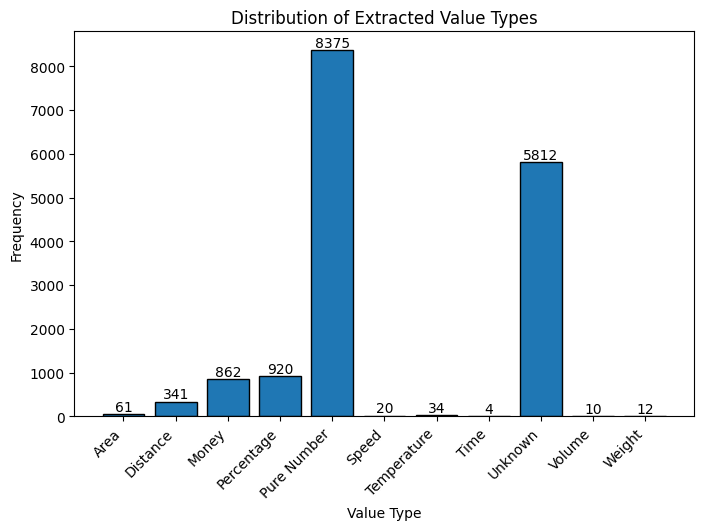

In [24]:
import matplotlib.pyplot as plt
import numpy as np

ans_types = [extract_value_type(ans) for ans in num_ans]

# Count occurrences of each type
unique_types, counts = np.unique(ans_types, return_counts=True)

plt.figure(figsize=(8, 5))  # Adjust figure size
bars = plt.bar(unique_types, counts, edgecolor='black')

# Rotate x-axis labels and align them with bars
plt.xticks(rotation=45, ha='right')

# Add labels on top of bars
for bar, count in zip(bars, counts):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count),
             ha='center', va='bottom', fontsize=10)

plt.xlabel("Value Type")
plt.ylabel("Frequency")
plt.title("Distribution of Extracted Value Types")

plt.show()

In [33]:
from knowledge_maze.tools.parse_answers import extract_number

all_count = 0
relevant_count = 0
percentage_values = []
for ans, ans_type, question in zip(num_ans, ans_types, num_ques):
    if ans_type == 'Unknown':
        if 'How many' not in question and 'how many' not in question and 'How much' not in question and 'how much' not in question and 'number' not in question:
        # percentage_values.append(extract_number(ans))
            print(f"{question} --> {ans}")
            relevant_count += 1
        all_count += 1
        # if 'How many' in question or 'how many' in question:
        #     relevant_count += 1
        # else:
        #     print(f"{question} --> {ans}")
print(f"{relevant_count} / {all_count}")

# plt.hist(percentage_values, bins=np.arange(0,100,10))
# plt.show()

To the nearest million, what is the population of London, England? --> 7 million
What was John Glenn/'s first spacecraft called? --> Mercury-Atlas 6
How old was Macaulay Culkin when he was cast for his role in Home Alone? --> Nine
By 1999 how may times had Jane Fonda been Oscar nominated? --> Seven
What is the boiling point of water? --> 100 degrees Celsius
How long does it take for the Earth to spin once on its axis? --> One Day 
What is the sum of the internal angles in a hexagon? --> 720 degrees
In which full-length cartoon are the main characters called Pongo and Perdita? --> 101 Dalmatians
How tall was Queen Victoria? 5 foot, 5 foot 5 or 5 foot 10? --> 5 foot
Before the most recent Christmas specials, how may episodes were there in which neither Uncle Albert or Grandad appeared? None, two or nine? --> Two
In the Bible, what is the Decalogue more commonly known as? --> Ten Commandments
What is the most times a piece of paper can be folded in half? --> Seven
Which playing card is kn

In [225]:
how_many = 0
for sample in reasoning_chains:
    for question in sample['Questions']:
        how_many += 1
print(how_many * (100) * 0.00000015)

1.9260149999999998


In [35]:
from knowledge_maze.create_dataset.create_reasoning_path import filter_ambiguous_questions

filtered_date_clusters_sample = {}
for i, sample in enumerate(filtered_date_clusters.items()):
    filtered_date_clusters_sample[sample[0]] = sample[1]
    if i == 20:
        break

results = await filter_ambiguous_questions(filtered_date_clusters_sample)

Usage cost: 0.0137$ (Estimated: 0.01$): 100%|████████████████████████████████████████| 476/476 [00:11<00:00, 42.33it/s]


In [36]:
results

{'Thursday': ['What day of the week was the Wall Street Crash?',
  'Dydd Iau is Welsh for which day of the week?',
  '‘Jeudi’ is French for which day of the week?',
  '‘Donnerstag’ is German for which day of the week?',
  '‘Jueves’ is Spanish for which day of the week?',
  'In the Hebrew calendar, Yom Chamishi corresponds with which day of the week?',
  'Which day of the week is named after the Norse god of thunder?',
  'In the Christian calendar, Maundy falls on which day of Holy Week?',
  'Which day of the week features in the title of a novel by G K Chesterton?',
  'General Elections are traditionally held on which day of the week in Britain?',
  'may 31 2018 is what day of the year',
  'when does the economist come out what day',
  'what day does the chester chronicle come out',
  'What day of the week was Spectre released in North America?',
  'What day of the week was September 15, 2011?',
  'What day of the week did the major earthquake strike Mexico City?'],
 'Sunday': ["New Ye

In [17]:
np.mean(list(results.values()))

0.05042016806722689

In [18]:
for question, result in results.items():
    if result:
        print(question)

who died first on what happened to monday
When does BYU refuse to play athletic games that got the attention of the sports networks?
luckiest day of the week to get married
On what day does the main parade take place?
What is the first on the list if these words are sorted based on the penultimate letter of each word?
Bell stopped using the liquid-based method after what month?
When did Elizabeth's mother die in 2002?
Instead of November, for what month of the following year was the release rescheduled?
Author H E Bates wrote the novel ‘The Darling Buds of….when’?
In which month of 1955 was this pact declared?
When is the final?
When did FIFA reject an appeal of the rules violation ruling?
when does it's a small world close
During which month is the complex particularly active? 
What month would the weather window begin to decline?
What month did Kelly Clarkson win?
What month has the most precipitation? 
When was the last time the torch had been in China?
What month did Bell go to Bos